In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])

Dataset Shape: (569, 30)
Number of Features: 30


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [4]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Features before PCA:", X_train_scaled.shape[1])
print("Features after PCA:", X_train_pca.shape[1])

Features before PCA: 30
Features after PCA: 2


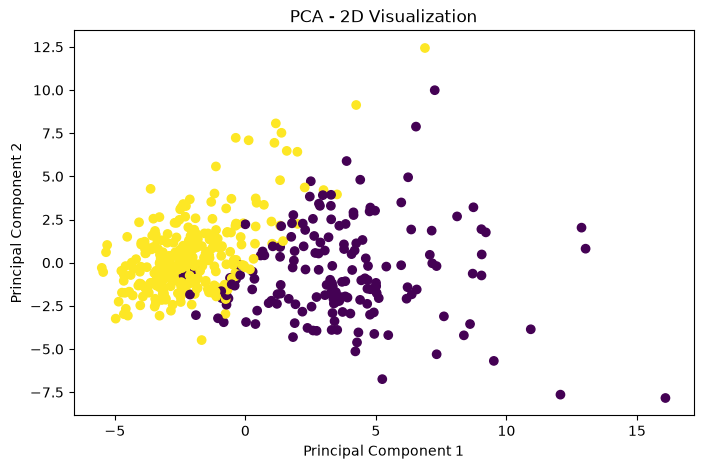

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D Visualization")
plt.show()

In [7]:
model1 = LogisticRegression(max_iter=1000)

model1.fit(X_train_scaled, y_train)

y_pred1 = model1.predict(X_test_scaled)

accuracy1 = accuracy_score(y_test, y_pred1)

print("Accuracy Before PCA:", accuracy1 * 100, "%")

Accuracy Before PCA: 97.36842105263158 %


In [8]:
model2 = LogisticRegression(max_iter=1000)

model2.fit(X_train_pca, y_train)

y_pred2 = model2.predict(X_test_pca)

accuracy2 = accuracy_score(y_test, y_pred2)

print("Accuracy After PCA:", accuracy2 * 100, "%")

Accuracy After PCA: 99.12280701754386 %


In [9]:
comparison = pd.DataFrame({
    "Method": ["Before PCA", "After PCA"],
    "Number of Features": [30, 2],
    "Accuracy (%)": [accuracy1 * 100, accuracy2 * 100]
})

print(comparison)

       Method  Number of Features  Accuracy (%)
0  Before PCA                  30     97.368421
1   After PCA                   2     99.122807
